# 02 · Match EDA

**Question: how is Barcelona actually performing?**

Results are the outcome; expected goals (xG) describe the chances that
produced them. This notebook looks at both across 17 seasons: results and
goals, xG for and against, home and away, scorelines, opponents, and the
coaching eras. The central question from the project plan is whether
**changes in xG difference correspond with changes in results**, and, more
usefully for modelling later, whether xG tells us something about *future*
results that past results do not.

Data notes from notebook 01:
* results, goals and points come from football-data (complete schedule);
* xG and other event metrics come from StatsBomb, which is Messi-centred and
  incomplete before 2008/09; those seasons are shown but flagged.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import statsmodels.api as sm
from scipy import stats

from barca import config, pipeline
from barca.analytics import results as res
from barca.analytics import team_match
from barca.data import normalize
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(2)

polars.config.Config

In [2]:
matches = normalize.matches(pl.read_parquet(config.INTERIM / "matches.parquet"))
events = normalize.events(pipeline.scan_events())
tms = team_match.team_match_stats(events, matches)
barca = tms.filter(pl.col("team") == "Barcelona").join(
    matches.select("match_id", "barca_era"), on="match_id"
)
league_barca = barca.filter(pl.col("competition") == "La Liga")

results = normalize.football_data_results(pl.read_parquet(config.INTERIM / "football_data.parquet"))
long = res.long_results(results)
schedule = long.filter(pl.col("team") == "Barcelona", pl.col("season_start").is_between(2004, 2020))
print(f"StatsBomb Barcelona matches: {barca.height} · complete league schedule: {schedule.height}")

StatsBomb Barcelona matches: 527 · complete league schedule: 646


## 1. Results by season

From the complete schedule (all 38 matches a season).

In [3]:
by_season = (
    schedule.group_by("season")
    .agg(
        (pl.col("result") == "W").sum().alias("W"),
        (pl.col("result") == "D").sum().alias("D"),
        (pl.col("result") == "L").sum().alias("L"),
        pl.col("points").sum().alias("points"),
        pl.col("goals").sum().alias("GF"),
        pl.col("goals_against").sum().alias("GA"),
    )
    .with_columns((pl.col("GF") - pl.col("GA")).alias("GD"), (pl.col("points") / 38).round(2).alias("PPG"))
    .sort("season")
)
by_season

season,W,D,L,points,GF,GA,GD,PPG
str,u32,u32,u32,i64,i64,i64,i64,f64
"""2004/2005""",25,9,4,84,73,29,44,2.21
"""2005/2006""",25,7,6,82,80,35,45,2.16
"""2006/2007""",22,10,6,76,78,33,45,2.00
"""2007/2008""",19,10,9,67,76,43,33,1.76
"""2008/2009""",27,6,5,87,105,35,70,2.29
"""2009/2010""",31,6,1,99,98,24,74,2.61
"""2010/2011""",30,6,2,96,95,21,74,2.53
"""2011/2012""",28,7,3,91,114,29,85,2.39
"""2012/2013""",32,4,2,100,115,40,75,2.63


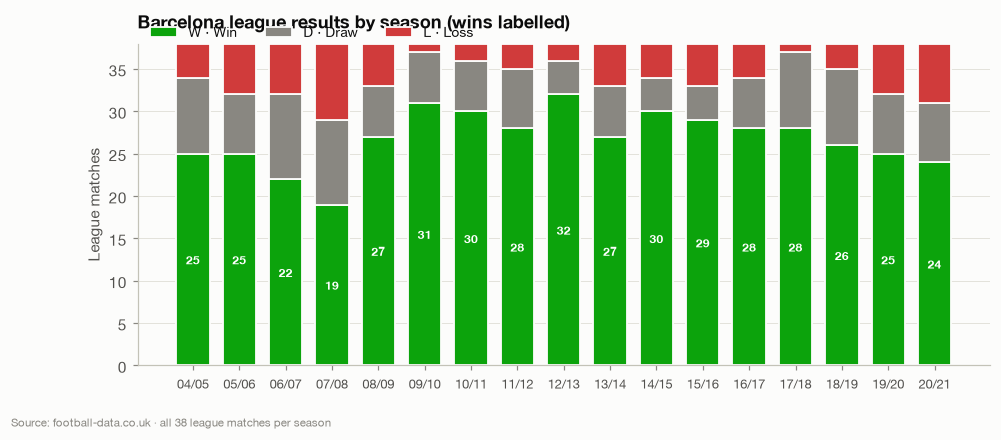

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(by_season.height)
labels = by_season["season"].str.slice(2, 2) + "/" + by_season["season"].str.slice(7, 2)
bottom = np.zeros(by_season.height)
names = {"W": "Win", "D": "Draw", "L": "Loss"}
for r in ("W", "D", "L"):
    vals = by_season[r].to_numpy()
    ax.bar(x, vals, bottom=bottom, color=style.RESULT_COLOURS[r], width=0.72, label=f"{r} · {names[r]}",
           edgecolor=style.SURFACE, linewidth=1.2)
    bottom += vals
for xi, w in zip(x, by_season["W"], strict=True):
    ax.text(xi, w / 2, str(w), ha="center", va="center", color="white", fontsize=8, fontweight="semibold")
ax.set_xticks(x, labels, fontsize=8.5)
ax.set_ylabel("League matches")
ax.set_ylim(0, 38)
ax.set_title("Barcelona league results by season (wins labelled)")
ax.legend(ncols=3, loc="upper left", bbox_to_anchor=(0, 1.1))
style.caption(ax, "Source: football-data.co.uk · all 38 league matches per season")
style.savefig(fig, "02_results_by_season")
plt.show()

The Guardiola peak (2008/09-2011/12) and the 2014/15-2015/16 treble era
average about 2.4-2.6 points per game. The decline after 2018/19 is visible:
fewer wins, more draws, and 2019/20-2020/21 are the two weakest seasons
since 2007/08.

## 2. Goals vs expected goals

xG answers a different question from goals: *how good were the chances?*
Per-match averages, with the partially covered early seasons drawn hollow.

In [5]:
xg_season = (
    league_barca.group_by("season")
    .agg(
        pl.len().alias("n"),
        pl.col("goals").mean().alias("goals"),
        pl.col("xg").mean().alias("xg"),
        pl.col("npxg").mean().alias("npxg"),
        pl.col("goals_against").mean().alias("goals_against"),
        pl.col("xga").mean().alias("xga"),
        pl.col("xg_diff").mean().alias("xg_diff"),
    )
    .join(by_season.select("season", "PPG"), on="season")
    .with_columns((pl.col("season").str.slice(0, 4).cast(pl.Int32) >= 2008).alias("reliable"))
    .sort("season")
)
xg_season.select("season", "n", "goals", "xg", "goals_against", "xga", "xg_diff", "PPG")

season,n,goals,xg,goals_against,xga,xg_diff,PPG
str,u32,f64,f32,f64,f32,f32,f64
"""2004/2005""",7,2.29,1.39,0.29,0.52,0.87,2.21
"""2005/2006""",17,2.53,2.30,0.71,0.74,1.56,2.16
"""2006/2007""",26,2.12,1.82,0.92,0.87,0.95,2.00
"""2007/2008""",27,2.11,1.68,1.15,0.96,0.72,1.76
"""2008/2009""",31,3.03,2.34,0.94,0.62,1.72,2.29
"""2009/2010""",35,2.66,1.82,0.66,0.76,1.06,2.61
"""2010/2011""",33,2.61,1.86,0.55,0.70,1.17,2.53
"""2011/2012""",37,3.00,2.20,0.76,0.75,1.45,2.39
"""2012/2013""",32,3.06,1.72,1.19,0.91,0.81,2.63


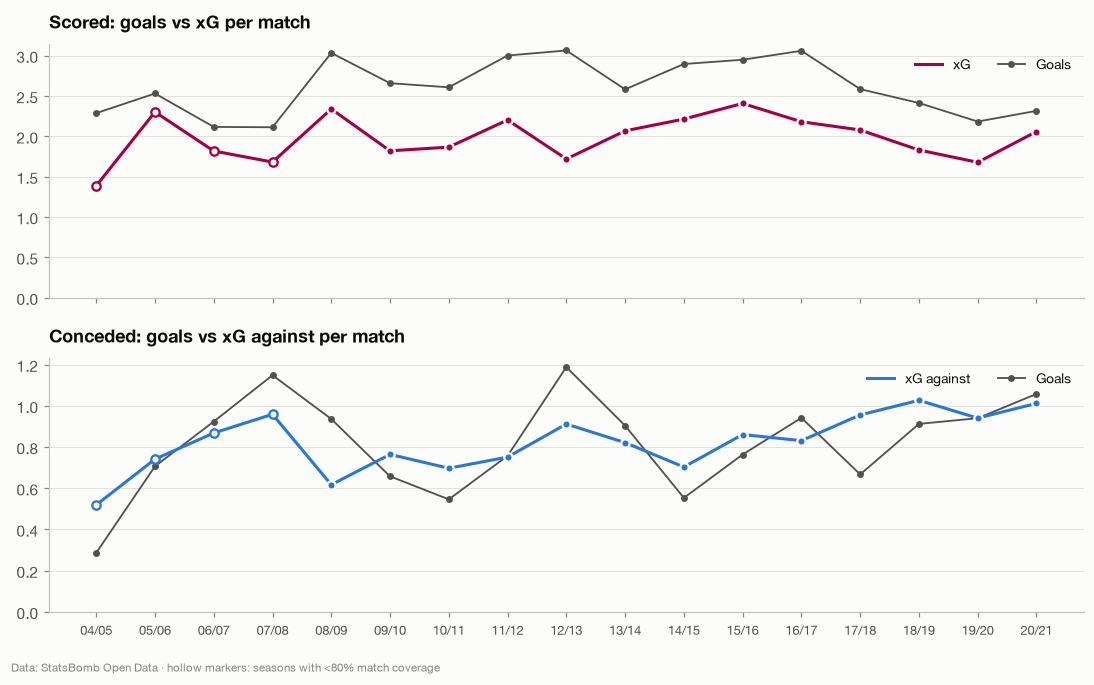

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x = np.arange(xg_season.height)
lab = xg_season["season"].str.slice(2, 2) + "/" + xg_season["season"].str.slice(7, 2)
rel = xg_season["reliable"].to_numpy()
for ax, g, e, title, colour in (
    (axes[0], "goals", "xg", "Scored: goals vs xG per match", style.BARCA),
    (axes[1], "goals_against", "xga", "Conceded: goals vs xG against per match", style.OPPONENT),
):
    ax.plot(x, xg_season[e], color=colour, lw=2, label="xG" if e == "xg" else "xG against", zorder=2)
    ax.scatter(x[rel], xg_season[e].to_numpy()[rel], color=colour, s=30, zorder=3,
               edgecolor=style.SURFACE, linewidth=1.5)
    ax.scatter(x[~rel], xg_season[e].to_numpy()[~rel], facecolor=style.SURFACE, edgecolor=colour, s=30, zorder=3,
               linewidth=1.5)
    ax.plot(x, xg_season[g], color=style.INK_2, lw=1.2, ls="-", marker="o", ms=3.5, label="Goals", zorder=1)
    ax.set_title(title)
    ax.legend(loc="upper right", ncols=2)
    ax.set_ylim(0, None)
axes[1].set_xticks(x, lab, fontsize=8.5)
style.caption(axes[1], style.STATSBOMB_CREDIT + " · hollow markers: seasons with <80% match coverage")
fig.tight_layout()
style.savefig(fig, "02_goals_vs_xg")
plt.show()

In [7]:
finishing = league_barca.select(
    (pl.col("goals").sum() - pl.col("xg").sum()).alias("goals_minus_xg"),
    (pl.col("np_goals").sum() - pl.col("npxg").sum()).alias("np_goals_minus_npxg"),
    (pl.col("goals_against").sum() - pl.col("xga").sum()).alias("conceded_minus_xga"),
    pl.len().alias("matches"),
)
finishing

goals_minus_xg,np_goals_minus_npxg,conceded_minus_xga,matches
f64,f64,f64,u32
333.53,292.42,-1.15,524


The two ends of the pitch behave very differently:

* **Barcelona outscore their xG in every single season**, by almost 300
  non-penalty goals over 524 league matches (about +0.56 a match). That is far
  too large and too consistent to be luck. It is the finishing of Messi (474
  league goals from about 325 xG in this data), Suárez, Eto'o and Villa,
  which a shot-level xG model built on the *average* finisher cannot see.
* **Goals conceded match xG against almost exactly** (−1 goal over the whole
  period). The xG model is well calibrated for the chances Barcelona allow.
  The gap is purely an attacking phenomenon.

For modelling, xG alone understates Barcelona's goal output. Rolling *goals*
and rolling *xG* go in side by side so a model can learn the gap.

## 3. Does xG difference correspond with results?

Match level first: the distribution of xG difference for wins, draws and
losses.

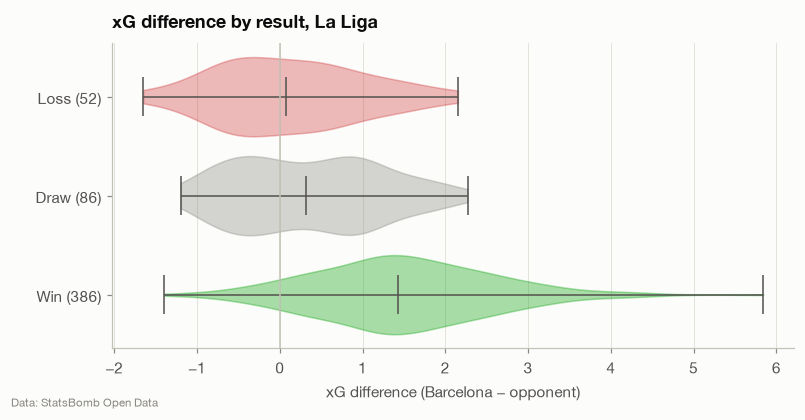

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
order = ["W", "D", "L"]
data = [league_barca.filter(pl.col("result") == r)["xg_diff"].to_numpy() for r in order]
parts = ax.violinplot(data, positions=range(3), vert=False, showmedians=True, widths=0.8)
for body, r in zip(parts["bodies"], order, strict=True):
    body.set_facecolor(style.RESULT_COLOURS[r])
    body.set_alpha(0.35)
    body.set_edgecolor(style.RESULT_COLOURS[r])
for key in ("cmedians", "cmins", "cmaxes", "cbars"):
    parts[key].set_color(style.INK_2)
    parts[key].set_linewidth(1)
ax.set_yticks(range(3), [f"{r} ({len(d)})" for r, d in zip(["Win", "Draw", "Loss"], data, strict=True)])
ax.axvline(0, color=style.AXIS, lw=1)
ax.set_xlabel("xG difference (Barcelona − opponent)")
ax.set_title("xG difference by result, La Liga")
ax.grid(axis="x", color=style.GRID)
ax.grid(axis="y", visible=False)
style.caption(ax, style.STATSBOMB_CREDIT)
style.savefig(fig, "02_xgd_by_result")
plt.show()

In [9]:
lr_frame = league_barca.select("xg_diff", (pl.col("result") == "W").cast(pl.Int8).alias("win")).to_pandas()
logit = sm.Logit(lr_frame["win"], sm.add_constant(lr_frame[["xg_diff"]])).fit(disp=False)
print(logit.summary2().tables[1].round(3))
print(f"McFadden pseudo-R²: {logit.prsquared:.3f}")
for v in (0.0, 0.5, 1.0, 2.0):
    p = logit.predict(np.array([[1.0, v]]))[0]
    print(f"P(win | xGD = {v:+.1f}) = {p:.2f}")

         Coef.  Std.Err.      z  P>|z|  [0.025  0.975]
const   -0.055     0.142 -0.387  0.699  -0.334   0.224
xg_diff  1.276     0.133  9.595  0.000   1.015   1.537
McFadden pseudo-R²: 0.225
P(win | xGD = +0.0) = 0.49
P(win | xGD = +0.5) = 0.64
P(win | xGD = +1.0) = 0.77
P(win | xGD = +2.0) = 0.92


Within a match, xG difference is strongly associated with winning: each
extra 0.5 of xG difference adds roughly 13-15 percentage points of win
probability. At **xGD = 0 Barcelona still win about half the time**, which
is the finishing edge again. The overlap between the violins is also large:
losses with a positive xG difference are common. One match is a noisy sample
of shots.

The more useful question is about **trends**. Does a run of good xG
difference line up with a run of good results? Rolling 10-match windows over
the reliable seasons:

Correlation of rolling-10 xGD with rolling-10 PPG (same window): 0.28


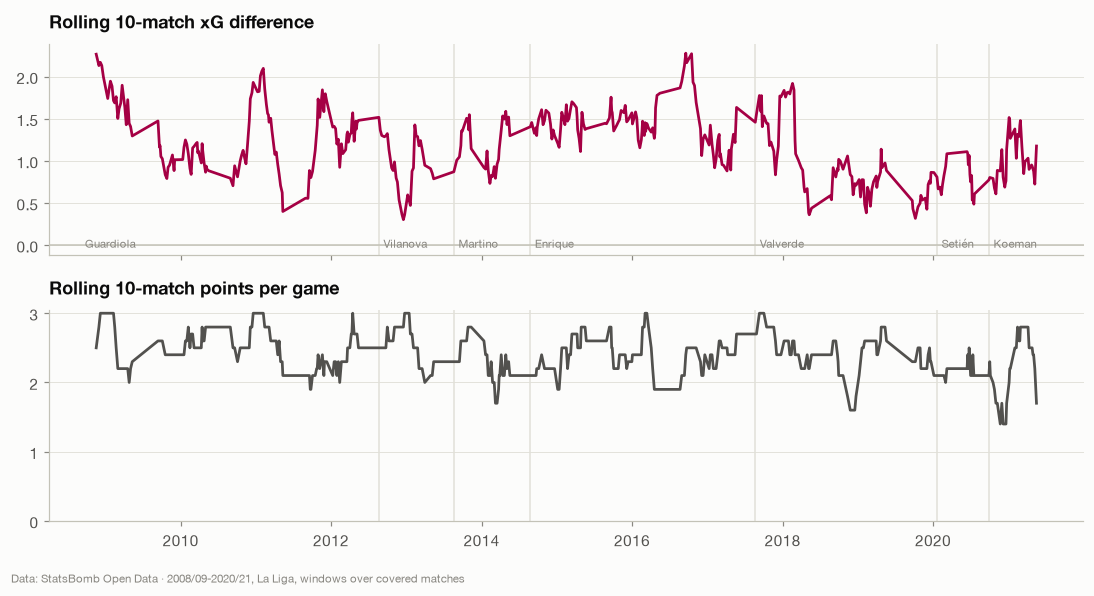

In [10]:
rel_matches = league_barca.filter(pl.col("season_start") >= 2008).sort("kickoff")
roll = rel_matches.with_columns(
    pl.col("xg_diff").rolling_mean(10).alias("xgd_10"),
    pl.col("points").cast(pl.Float64).rolling_mean(10).alias("ppg_10"),
    (pl.col("goals") - pl.col("goals_against")).cast(pl.Float64).rolling_mean(10).alias("gd_10"),
)
r_same = roll.drop_nulls("xgd_10").select(pl.corr("xgd_10", "ppg_10")).item()
print(f"Correlation of rolling-10 xGD with rolling-10 PPG (same window): {r_same:.2f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
axes[0].plot(roll["kickoff"], roll["xgd_10"], color=style.BARCA, lw=1.8)
axes[0].axhline(0, color=style.AXIS, lw=1)
axes[0].set_title("Rolling 10-match xG difference")
axes[1].plot(roll["kickoff"], roll["ppg_10"], color=style.INK_2, lw=1.8)
axes[1].set_title("Rolling 10-match points per game")
axes[1].set_ylim(0, 3.05)
eras = rel_matches.group_by("barca_era").agg(pl.col("kickoff").min().alias("start")).sort("start")
for ax in axes:
    for start in eras["start"][1:]:
        ax.axvline(start, color=style.GRID, lw=1, zorder=0)
for name, start in eras.iter_rows():
    axes[0].annotate(name.split()[-1], xy=(start, 0), xycoords=("data", "axes fraction"), xytext=(3, 3),
                     textcoords="offset points", fontsize=7.5, color=style.MUTED, va="bottom")
style.caption(axes[1], style.STATSBOMB_CREDIT + " · 2008/09-2020/21, La Liga, windows over covered matches")
fig.tight_layout()
style.savefig(fig, "02_rolling_xgd_ppg")
plt.show()

The two series are positively but only **moderately** correlated
(r ≈ 0.28). Over a 10-match window, finishing and goalkeeping variance still
decide a lot of points, and Barcelona's points per game has little room to
move (it rarely leaves the 2-3 band). The sustained low of 2019/20-2020/21
shows up in both panels.

### Is xG a better guide to the *future* than results are?

This is the question that matters for prediction. For each match, compare
three summaries of the previous 10 matches (points, goal difference, xG
difference) with the points won in the *next* 10.

In [11]:
fwd = roll.with_columns(
    pl.col("points").cast(pl.Float64).rolling_mean(10).shift(-10).alias("ppg_next_10"),
).drop_nulls(["xgd_10", "ppg_next_10"])
rows = []
for col, label in (("ppg_10", "points, last 10"), ("gd_10", "goal difference, last 10"),
                   ("xgd_10", "xG difference, last 10")):
    r, p = stats.pearsonr(fwd[col], fwd["ppg_next_10"])
    rows.append({"predictor": label, "corr_with_next_10_ppg": round(r, 3), "p_value": f"{p:.1e}"})
pl.DataFrame(rows)

predictor,corr_with_next_10_ppg,p_value
str,f64,str
"""points, last 10""",-0.03,"""5.8e-01"""
"""goal difference, last 10""",0.09,"""7.0e-02"""
"""xG difference, last 10""",0.12,"""1.5e-02"""


All three are weak predictors on their own. Barcelona's level is stable, so
there is little between-window variation to explain. **The ordering is the
informative part**: past points carry essentially no forward signal
(r ≈ 0), goal difference a little, and xG difference the most (r ≈ 0.12, the
only one clearly distinguishable from zero). Results are noisier than the
chances that produce them, and xG averages some of that noise out. Windows
overlap, so the p-values are optimistic, but the ordering matches what is
known in football analytics generally.

**Implication for feature engineering:** rolling xG and xGA are expected to
be more informative than rolling points. Both go into the feature set and
the models decide.

## 4. Home and away

In [12]:
venue = schedule.group_by("is_home").agg(
    pl.len().alias("matches"),
    pl.col("points").mean().alias("ppg"),
    pl.col("goals").mean().alias("gf"),
    pl.col("goals_against").mean().alias("ga"),
    (pl.col("result") == "W").mean().alias("win_rate"),
).join(
    league_barca.group_by("is_home").agg(
        pl.col("xg").mean().alias("xg"), pl.col("xga").mean().alias("xga"),
        pl.col("possession").mean().alias("possession"),
    ),
    on="is_home",
).sort("is_home", descending=True)
venue

is_home,matches,ppg,gf,ga,win_rate,xg,xga,possession
bool,u32,f64,f64,f64,f64,f32,f32,f64
true,323,2.55,2.88,0.72,0.81,2.27,0.73,0.66
false,323,2.04,2.17,0.98,0.60,1.75,0.94,0.65


In [13]:
league_all = long.filter(pl.col("season_start").is_between(2004, 2020))
league_home = league_all.filter(pl.col("is_home")).select(
    (pl.col("result") == "W").mean().alias("home_win"),
    (pl.col("result") == "D").mean().alias("draw"),
    (pl.col("result") == "L").mean().alias("away_win"),
    pl.col("goals").mean().alias("home_goals"),
    pl.col("goals_against").mean().alias("away_goals"),
)
league_home

home_win,draw,away_win,home_goals,away_goals
f64,f64,f64,f64,f64
0.47,0.25,0.28,1.55,1.13


Barcelona take roughly half a point per game more at home, create more and
concede less. League-wide, home teams win about 47% of La Liga matches and
away teams 28%.
Home advantage is a real, stable effect, and it will be a feature and a
parameter in the Elo model.

## 5. Scorelines

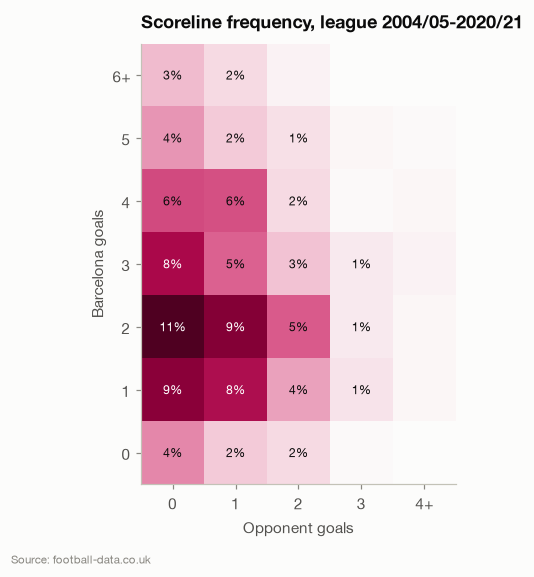

goals,goals_against,n,share
i16,i16,u32,f64
2,0,69,0.11
2,1,58,0.09
1,0,57,0.09
3,0,50,0.08
1,1,49,0.08
4,0,37,0.06
4,1,36,0.06
2,2,34,0.05


In [14]:
sc = (
    schedule.group_by("goals", "goals_against").agg(pl.len().alias("n"))
    .with_columns((pl.col("n") / pl.col("n").sum()).alias("share"))
)
grid = np.zeros((7, 5))
for g, a, n, s in sc.iter_rows():
    grid[min(g, 6), min(a, 4)] += s
fig, ax = plt.subplots(figsize=(5.2, 5.2))
im = ax.imshow(grid, cmap=style.HEAT, origin="lower")
for i in range(7):
    for j in range(5):
        if grid[i, j] >= 0.005:
            ax.text(j, i, f"{grid[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if grid[i, j] > 0.06 else style.INK)
ax.set_xticks(range(5), ["0", "1", "2", "3", "4+"])
ax.set_yticks(range(7), ["0", "1", "2", "3", "4", "5", "6+"])
ax.set_xlabel("Opponent goals")
ax.set_ylabel("Barcelona goals")
ax.set_title("Scoreline frequency, league 2004/05-2020/21")
ax.grid(False)
style.caption(ax, "Source: football-data.co.uk")
style.savefig(fig, "02_scorelines")
plt.show()
sc.sort("n", descending=True).head(8)

2-0 is the most common Barcelona scoreline (11%), followed by 2-1 and 1-0,
and clean sheets are frequent. The mass sits well above the diagonal. This matrix is what the
score model (milestone 12) has to reproduce. Independent Poisson models
typically underestimate low-scoring draws, and a Dixon-Coles correction
exists for that; it will be checked against this table.

## 6. Opponents

Where do the points get dropped?

In [15]:
opp = (
    schedule.group_by("opponent")
    .agg(
        pl.len().alias("matches"),
        pl.col("points").mean().alias("ppg"),
        (pl.col("goals") - pl.col("goals_against")).mean().alias("gd_per_game"),
    )
    .filter(pl.col("matches") >= 20)
    .join(
        league_barca.group_by("opponent").agg(pl.col("xg_diff").mean().alias("xgd_per_game")),
        on="opponent", how="left",
    )
    .sort("ppg")
)
opp

opponent,matches,ppg,gd_per_game,xgd_per_game
str,u32,f64,f64,f32
"""Real Madrid""",34,1.62,0.59,0.18
"""Valencia""",34,1.85,0.91,0.89
"""Atlético Madrid""",34,1.85,0.91,0.61
"""Celta Vigo""",22,1.95,1.14,0.78
"""Osasuna""",26,2.15,1.92,1.65
"""Real Sociedad""",28,2.18,1.32,0.82
"""Villarreal""",32,2.19,1.19,1.09
"""Deportivo La Coruña""",24,2.25,1.71,1.58
"""Espanyol""",32,2.25,1.56,1.30


Real Madrid, Atlético, Valencia and (less obviously) Celta Vigo are where
Barcelona drop the most points. Against Real Madrid the xG difference is
close to zero, a genuinely even fixture. Weaker opponents yield 2.3-2.6
points a game. Opponent strength is clearly a first-order factor. This is exactly
what an Elo rating is meant to quantify, rather than relying on the club's
name.

## 7. Coaching eras

Style and output by head coach (reliable seasons only for event metrics).

In [16]:
era = (
    barca.filter(pl.col("competition") == "La Liga")
    .group_by("barca_era")
    .agg(
        pl.len().alias("matches"),
        pl.col("kickoff").min().alias("from"),
        pl.col("points").mean().alias("ppg"),
        pl.col("xg").mean().alias("xg"),
        pl.col("xga").mean().alias("xga"),
        pl.col("possession").mean().alias("possession"),
        pl.col("field_tilt").mean().alias("field_tilt"),
        pl.col("ppda").mean().alias("ppda"),
        pl.col("defensive_action_height").mean().alias("def_height"),
        pl.col("progressive_passes").mean().alias("prog_passes"),
    )
    .sort("from")
    .drop("from")
)
era

barca_era,matches,ppg,xg,xga,possession,field_tilt,ppda,def_height,prog_passes
str,u32,f64,f32,f32,f64,f64,f64,f32,f64
"""Frank Rijkaard""",77,2.23,1.84,0.84,0.62,0.62,10.77,51.33,72.10
"""Pep Guardiola""",136,2.49,2.05,0.71,0.68,0.73,11.23,54.27,97.43
"""Tito Vilanova""",32,2.56,1.72,0.91,0.68,0.71,14.24,53.15,99.91
"""Gerardo Martino""",31,2.23,2.07,0.82,0.67,0.73,12.24,53.27,98.16
"""Luis Enrique""",110,2.44,2.27,0.80,0.67,0.71,12.02,54.20,100.62
"""Ernesto Valverde""",84,2.38,1.89,0.98,0.63,0.66,14.43,54.31,90.51
"""Quique Setién""",19,2.21,1.77,0.93,0.69,0.72,13.50,55.30,94.53
"""Ronald Koeman""",35,2.06,2.06,1.01,0.65,0.72,15.81,55.11,96.34


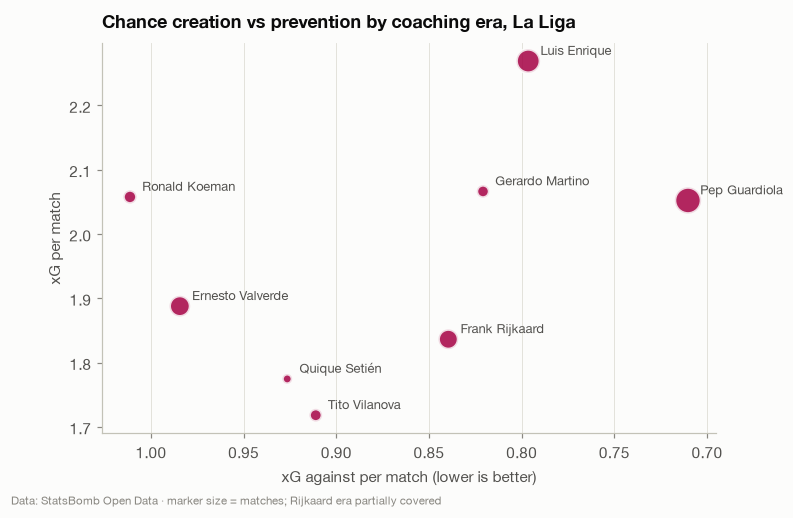

In [17]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))
e = era.filter(pl.col("matches") >= 19)
ax.scatter(e["xga"], e["xg"], s=e["matches"] * 2.2, color=style.BARCA, alpha=0.85, edgecolor=style.SURFACE,
           linewidth=2, zorder=3)
for name, xg_, xga_ in e.select("barca_era", "xg", "xga").iter_rows():
    ax.annotate(name, (xga_, xg_), xytext=(8, 4), textcoords="offset points", fontsize=8.5, color=style.INK_2)
ax.set_xlabel("xG against per match (lower is better)")
ax.set_ylabel("xG per match")
ax.invert_xaxis()
ax.grid(axis="both")
ax.set_title("Chance creation vs prevention by coaching era, La Liga")
style.caption(ax, style.STATSBOMB_CREDIT + " · marker size = matches; Rijkaard era partially covered")
style.savefig(fig, "02_eras")
plt.show()

Guardiola's teams conceded the fewest chances (0.71 xG against a match).
Luis Enrique's created the most (2.27 xG) and had the best xG difference of
any era (+1.47). From Valverde onwards xG against sits at 0.93-1.01 a match
while possession stays around 65%: Barcelona kept the ball but stopped
suppressing chances. PPDA drifts upwards over the period, from about 11 under
Rijkaard and Guardiola to 14-16 under Valverde and Koeman, meaning less
intense pressing in the opponent's half. That is a style change worth
testing as a feature (pressing intensity).

## 8. Interactive timeline

A Plotly version of the match-by-match xG timeline, saved as a standalone
HTML file for exploration (`reports/interactive/xg_timeline.html`).

In [18]:
tl = league_barca.sort("kickoff").with_columns(
    pl.col("xg_diff").rolling_mean(10).alias("xgd_10"),
    (pl.col("opponent") + " " + pl.col("goals").cast(pl.String) + "-" + pl.col("goals_against").cast(pl.String)
     + " (" + pl.when(pl.col("is_home")).then(pl.lit("H")).otherwise(pl.lit("A")) + ")").alias("label"),
)
figp = go.Figure()
figp.add_trace(go.Bar(x=tl["kickoff"], y=tl["xg_diff"], name="xG difference",
                      marker_color=[style.RESULT_COLOURS[r] for r in tl["result"]],
                      hovertext=tl["label"], hovertemplate="%{hovertext}<br>xGD %{y:.2f}<extra></extra>"))
figp.add_trace(go.Scatter(x=tl["kickoff"], y=tl["xgd_10"], name="10-match average", line={"color": style.INK, "width": 2}))
figp.update_layout(template="simple_white", height=420, title="Barcelona xG difference per league match",
                   hovermode="x unified", legend={"orientation": "h", "y": 1.08})
out = config.REPORTS / "interactive"
out.mkdir(exist_ok=True)
figp.write_html(out / "xg_timeline.html", include_plotlyjs="cdn")
print("written", out / "xg_timeline.html")

written reports/interactive/xg_timeline.html


## Findings

1. **Performance peaked 2008/09-2016/17 and declined after 2018/19**, both in
   results and in xG difference. The decline is mostly defensive: xG against
   rose from ~0.7-0.8 to ~1.0 a match while xG created held up better.
2. **xG difference and results move together** (moderately), and over a
   10-match horizon **past xG difference predicts future points better than
   past points do**. Rolling xG/xGA features should outperform rolling
   results.
3. **Barcelona outscore their xG massively** (+0.56 non-penalty goals a
   match) while conceding exactly what xG predicts. Goals and xG carry
   complementary information in attack.
4. **Home advantage is large and stable** (league-wide home win rate ≈47%).
5. **Opponent quality dominates**: points are dropped against a small set of
   strong clubs. It needs a proper strength rating (Elo), not club names.
6. **Style drifted**: pressing intensity (PPDA) and chance prevention
   weakened after the Luis Enrique era even as possession stayed high.

Next: what is inside the event stream (`03_event_eda`).